<a href="https://colab.research.google.com/github/MajedMMH/Student-Behaviour-CNN/blob/main/Student_Behaviour_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import PIL
import pathlib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

tf.random.set_seed(42)

# 1. Business Understanding

## Student Behaviour Classification Using CNN

### 1. Project Overview
This project aims to develop a CNN model to classify student behaviors from classroom images.

The model focuses on three classes:
- Hand Raising
- Reading
- Writing

### 2. Business Problem
Teachers may find it difficult to continuously monitor all students in a classroom. An AI-based system can help recognize student behaviors automatically and provide insights into classroom engagement.

### 3. Project Objectives
- Develop a CNN-based classification model.
- Identify three student behaviors.
- Use the SCB-dataset-3 dataset.
- Explore the application of deep learning in classroom monitoring.

### 4. Project Scope
The project is limited to three behaviors: hand raising, reading, and writing.

Other behaviors, such as sleeping, talking, and using mobile phones, are considered possible future extensions.

### 5. Expected Outcomes
A trained CNN model capable of classifying student images into the three selected behavior categories.

### 6. Future Improvements
- Add more student behavior categories.
- Test the system in real classrooms.
- Develop a real-time monitoring application.


# 2. Data Understanding

In [ ]:
dataset_url = "https://drive.usercontent.google.com/download?id=1Ax29bNB54fXodYJ1KIjSuHVR9_k1jRHP&export=download&confirm=t"
tf.keras.utils.get_file('student_behaviour.zip', origin=dataset_url, cache_dir='.', extract=True)

72719741/72719741 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


'./datasets/student_behaviour_extracted'

In [ ]:
data_dir = pathlib.Path('/content/datasets/student_behaviour_extracted/student_behaviour')
data_dir

PosixPath('/content/datasets/student_behaviour_extracted/student_behaviour')

In [ ]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

23429


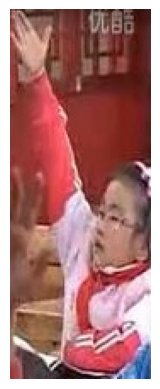

In [ ]:
hand_raising_images = list(data_dir.glob('hand-raising/*'))
plt.imshow(PIL.Image.open(hand_raising_images[0]))
plt.axis('off')
plt.show()

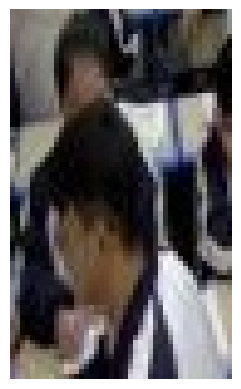

In [ ]:
reading_images = list(data_dir.glob('reading/*'))
plt.imshow(PIL.Image.open(reading_images[1]))
plt.axis('off')
plt.show()

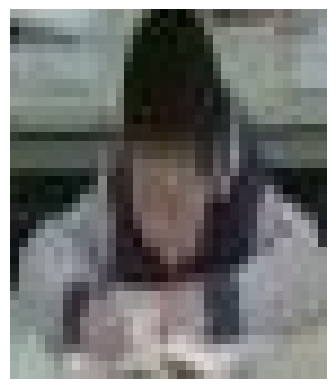

In [ ]:
writing_images = list(data_dir.glob('writing/*'))
plt.imshow(PIL.Image.open(writing_images[1]))
plt.axis('off')
plt.show()

In [ ]:
print(len(hand_raising_images), len(reading_images), len(writing_images))

10364 9573 3492


# 3. Data Preparation

In [ ]:
behaviour_images = {
    'hand-raising': hand_raising_images,
    'reading': reading_images,
    'writing': writing_images,
}

In [ ]:
behaviour_labels = {
    'hand-raising': 0,
    'reading': 1,
    'writing': 2,
}

In [ ]:
cv2.imread(str(hand_raising_images[0])).shape

(218, 83, 3)

In [ ]:
X, y = [], []

for behaviour, image_paths in behaviour_images.items():
    for image_path in image_paths:
        img = cv2.imread(str(image_path))
        X.append(cv2.resize(img, (64, 64)))
        y.append(behaviour_labels[behaviour])

In [ ]:
X = np.array(X)
y = np.array(y)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

In [ ]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

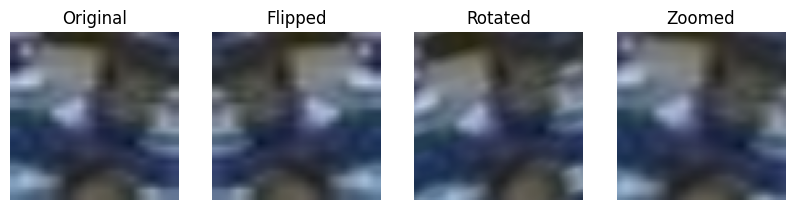

In [ ]:
flipped = layers.RandomFlip("horizontal", seed=3)(X_train[:1], training=True)
rotated = layers.RandomRotation(0.1, seed=7)(X_train[:1], training=True)
zoomed = layers.RandomZoom(0.1, seed=5)(X_train[:1], training=True)

images = [X_train[0], flipped[0], rotated[0], zoomed[0]]
titles = ['Original', 'Flipped', 'Rotated', 'Zoomed']
plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(np.array(images[i]).astype('uint8')[:, :, ::-1])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# 4. Modeling
Reference: [Flower CNN notebook](https://colab.research.google.com/drive/1VDc_TOCuG4eJ45Idv4aEYQDUQ2Yu7Rfp) — follow its model cells, from "Build convolutional neural network" to the end.
Changes: input shape `(64, 64, 3)` and last layer `Dense(3, activation='softmax')`. `data_augmentation` is already defined in section 3.

### Build convolutional neural network and train it

In [ ]:
num_classes = 3

model = Sequential([
  layers.Input(shape=(64, 64, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 548,387 (2.09 MB)

 Trainable params: 548,387 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.6365 - loss: 0.8053
Epoch 2/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7033 - loss: 0.6764
Epoch 3/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7414 - loss: 0.5953
Epoch 4/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7777 - loss: 0.5160
Epoch 5/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8165 - loss: 0.4351
Epoch 6/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8500 - loss: 0.3655
Epoch 7/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8728 - loss: 0.3111
Epoch 8/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9043 - loss: 0.2472
Epoch 9/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9232 - loss: 0.2010
Epoch 10/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9388 - loss: 0.1567
Epoch 11/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9473 - loss: 0.1382
Epoch 12/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/st

In [ ]:
model.evaluate(X_test_scaled, y_test)

147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7258 - loss: 2.4539


[2.4538989067077637, 0.7257789373397827]

In [ ]:
predictions = model.predict(X_test_scaled)
predictions[0]

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


array([0.01987159, 0.8949882 , 0.08514014], dtype=float32)

In [ ]:
np.argmax(predictions[0])

np.int64(1)

In [ ]:
y_test[0]

np.int64(0)

### Improve test accuracy using data augmentation and a dropout layer

In [ ]:
model_aug = Sequential([
  layers.Input(shape=(64, 64, 3)),
  data_augmentation,
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

model_aug.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

model_aug.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 548,387 (2.09 MB)

 Trainable params: 548,387 (2.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_aug = model_aug.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.5898 - loss: 0.8873
Epoch 2/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6261 - loss: 0.8160
Epoch 3/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6521 - loss: 0.7788
Epoch 4/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6648 - loss: 0.7549
Epoch 5/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6760 - loss: 0.7361
Epoch 6/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6869 - loss: 0.7122
Epoch 7/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6979 - loss: 0.6946
Epoch 8/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7032 - loss: 0.6793
Epoch 9/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7075 - loss: 0.6739
Epoch 10/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7139 - loss: 0.6586
Epoch 11/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7239 - loss: 0.6405
Epoch 12/30
586/586 ━━━━━━━━━━━━━━━━━━━━ 5s

In [ ]:
model_aug.evaluate(X_test_scaled, y_test)

147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7542 - loss: 0.5952


[0.5951529741287231, 0.7541613578796387]

### Compare the two models

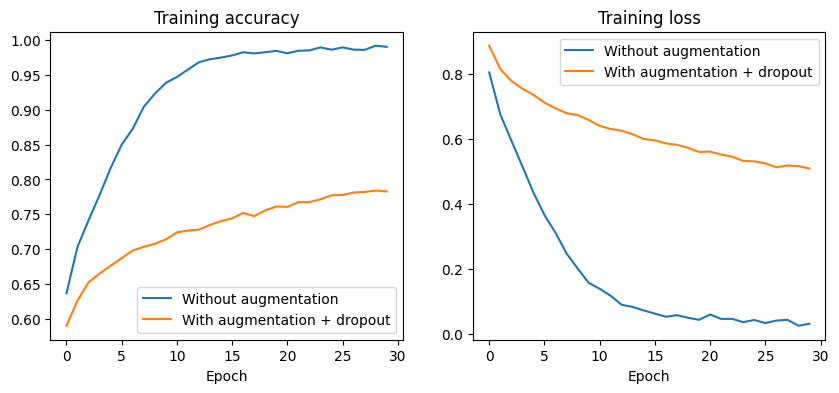

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Without augmentation')
plt.plot(history_aug.history['accuracy'], label='With augmentation + dropout')
plt.title('Training accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Without augmentation')
plt.plot(history_aug.history['loss'], label='With augmentation + dropout')
plt.title('Training loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [ ]:
_, train_acc = model.evaluate(X_train_scaled, y_train, verbose=0)
_, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
_, train_acc_aug = model_aug.evaluate(X_train_scaled, y_train, verbose=0)
_, test_acc_aug = model_aug.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Model 1 (no augmentation):     train {train_acc:.2%}  test {test_acc:.2%}")
print(f"Model 2 (augmentation+dropout): train {train_acc_aug:.2%}  test {test_acc_aug:.2%}")

best_model = model_aug if test_acc_aug >= test_acc else model
print("Best model:", "Model 2" if best_model is model_aug else "Model 1")

Model 1 (no augmentation):     train 96.62%  test 72.58%
Model 2 (augmentation+dropout): train 81.21%  test 75.42%
Best model: Model 2


# 5. Evaluation
Reference: [CIFAR-10 CNN notebook](https://colab.research.google.com/drive/190WdgRLeIyUbzQ0Ir0mEEAWPggmSosBg) — follow its last cells: `evaluate`, `predict`, `confusion_matrix`, `ConfusionMatrixDisplay` and `classification_report`.
Use the best model from section 4 with `X_test_scaled` and `y_test`.

# 6. Deployment
Reference: [Dogs vs Cats notebook](https://colab.research.google.com/drive/1ltb3NNJZvbMNHej17tDSdC-uYWI6izKF) — follow its "Predictive System" cell (last cell).
Read a new image, resize it to 64×64, scale it, predict, and print the class name.